## Working directory and import libraries

In [12]:
%load_ext autoreload
%autoreload 2

import os
import sys
import json
import cv2
import torch
import ultralytics
from pathlib import Path

PROJECT_ROOT = "/home/user/NeuroVision-AI-2"

os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))
os.environ["PROJECT_ROOT"] = str(PROJECT_ROOT)
print("Working directory:", os.getcwd())

# import cfgs
from src.config import cfg

#  Quick check
print("python      :", sys.version.split()[0])
print("torch       :", torch.__version__, "| CUDA:", torch.cuda.is_available())
print("ultralytics :", ultralytics.__version__)
print("opencv      :", cv2.__version__)

print("Raw data :", cfg.RAW_DIR)
print("Classes  :", cfg.CLASS_NAMES)
print("Split    : train %.0f%% / val %.0f%% / test %.0f%%" % (
    (1 - cfg.VAL_RATIO - cfg.TEST_RATIO) * 100, cfg.VAL_RATIO * 100, cfg.TEST_RATIO * 100))
print("Seed     :", cfg.SEED)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Working directory: /home/user/NeuroVision-AI-2
python      : 3.10.22
torch       : 2.14.1+cu130 | CUDA: True
ultralytics : 8.4.192
opencv      : 5.0.0
Raw data : /home/user/NeuroVision-AI-2/data/raw
Classes  : ('Glioma', 'Meningioma', 'No Tumor', 'Pituitary')
Split    : train 70% / val 15% / test 15%
Seed     : 42


## Configuration and MLflow connection

In [13]:
from src.config import cfg
from src.mlflow_utils import start_tracking

start_tracking(experiment="neurovision-yolov8")
print(json.dumps(cfg.to_dict(), indent=2)[:600], "...")

MLflow tracking: http://localhost:5000 | experiment: neurovision-yolov8 (id 1)
{
  "SEED": 42,
  "PROJECT_ROOT": "/home/user/NeuroVision-AI-2",
  "RAW_DIR": "/home/user/NeuroVision-AI-2/data/raw",
  "DATA_DIR": "/home/user/NeuroVision-AI-2/data",
  "DATA_YAML": "/home/user/NeuroVision-AI-2/data/data.yaml",
  "MODELS_DIR": "/home/user/NeuroVision-AI-2/models",
  "RUNS_DIR": "/home/user/NeuroVision-AI-2/runs",
  "VAL_RATIO": 0.15,
  "TEST_RATIO": 0.15,
  "RAW_SPLIT_DIR": "/home/user/NeuroVision-AI-2/data/raw_split",
  "CLASS_NAMES": [
    "Glioma",
    "Meningioma",
    "No Tumor",
    "Pituitary"
  ],
  "IMAGE_SIZE": 640,
  "BATCH_SIZE": 16,
  "EPOCHS": 30,
  "PATIENCE":  ...


## Check the Vast GPU

In [14]:
from src.train import check_gpu

gpu = check_gpu()
print(json.dumps(gpu, indent=2))

{
  "cuda_available": true,
  "torch_version": "2.14.1+cu130",
  "cuda_version": "13.0",
  "device_count": 1,
  "device_name": "NVIDIA TITAN RTX",
  "total_memory_gb": 23.5,
  "free_memory_gb": 20.6
}


## Augmentation: settings and visual check

{
  "degrees": 10.0,
  "translate": 0.1,
  "scale": 0.3,
  "hsv_v": 0.2,
  "fliplr": 0.0,
  "flipud": 0.0,
  "hsv_h": 0.0,
  "hsv_s": 0.0,
  "mosaic": 0.0,
  "mixup": 0.0,
  "shear": 0.0,
  "perspective": 0.0
}
Ultralytics 8.4.192 🚀 Python-3.10.22 torch-2.14.1+cu130 CUDA:0 (NVIDIA TITAN RTX, 24023MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=6, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/user/NeuroVision-AI-2/data/data.yaml, degrees=10.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=0.01, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.2, imgsz=640, iou=0

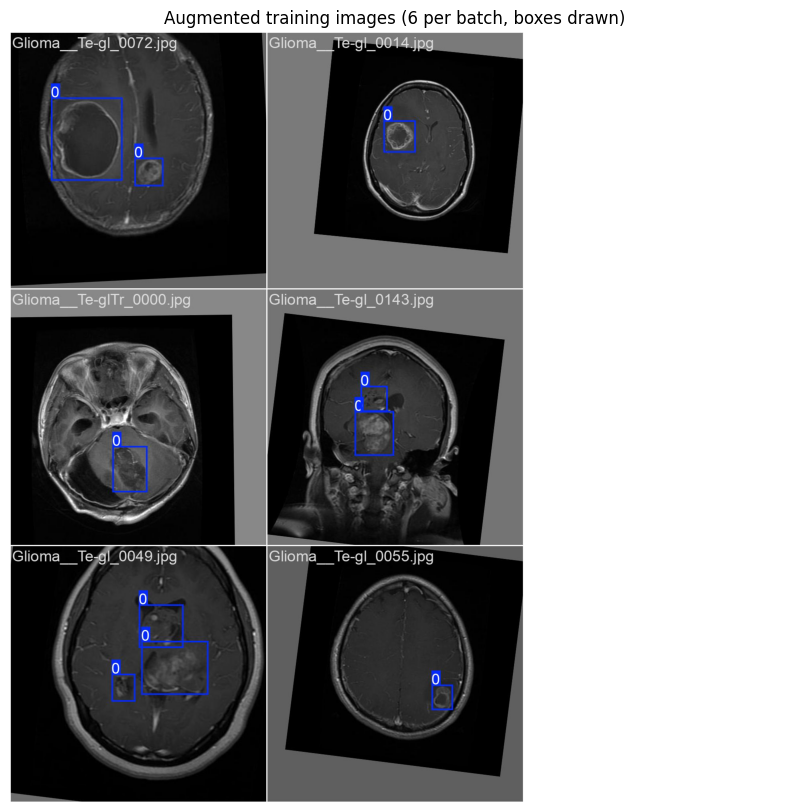

PosixPath('/home/user/NeuroVision-AI-2/runs/augmentation_preview/preview/train_batch0.jpg')

In [15]:
from src.config import AUGMENTATION
from src.train import preview_augmentation

print(json.dumps(AUGMENTATION, indent=2))
preview_augmentation(n=6)       # augmented training images with their boxes

## One-epoch test

In [10]:
from src.train import train_yolo

smoke = train_yolo(model_name="yolov8n.pt", epochs=1, run_name="smoke-test", mlflow_log=False)
print(smoke["run_dir"], "| duration: %.0f s" % smoke["duration_s"])

Ultralytics 8.4.192 🚀 Python-3.10.22 torch-2.14.1+cu130 CUDA:0 (NVIDIA TITAN RTX, 24023MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/user/NeuroVision-AI-2/data/data.yaml, degrees=10.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.2, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=smoke-test, nbs=64, nms=None, opset=None

## Full training, baseline

In [16]:
baseline = train_yolo(model_name="yolov8n.pt", run_name="yolov8n-baseline")
print("run dir  :", baseline["run_dir"])
print("duration : %.1f min" % (baseline["duration_s"] / 60))
print(json.dumps(baseline["metrics"], indent=2))

Ultralytics 8.4.192 🚀 Python-3.10.22 torch-2.14.1+cu130 CUDA:0 (NVIDIA TITAN RTX, 24023MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/user/NeuroVision-AI-2/data/data.yaml, degrees=10.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.2, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=yolov8n-baseline-2, nbs=64, nms=None, o

## Read the curves and detect overfitting

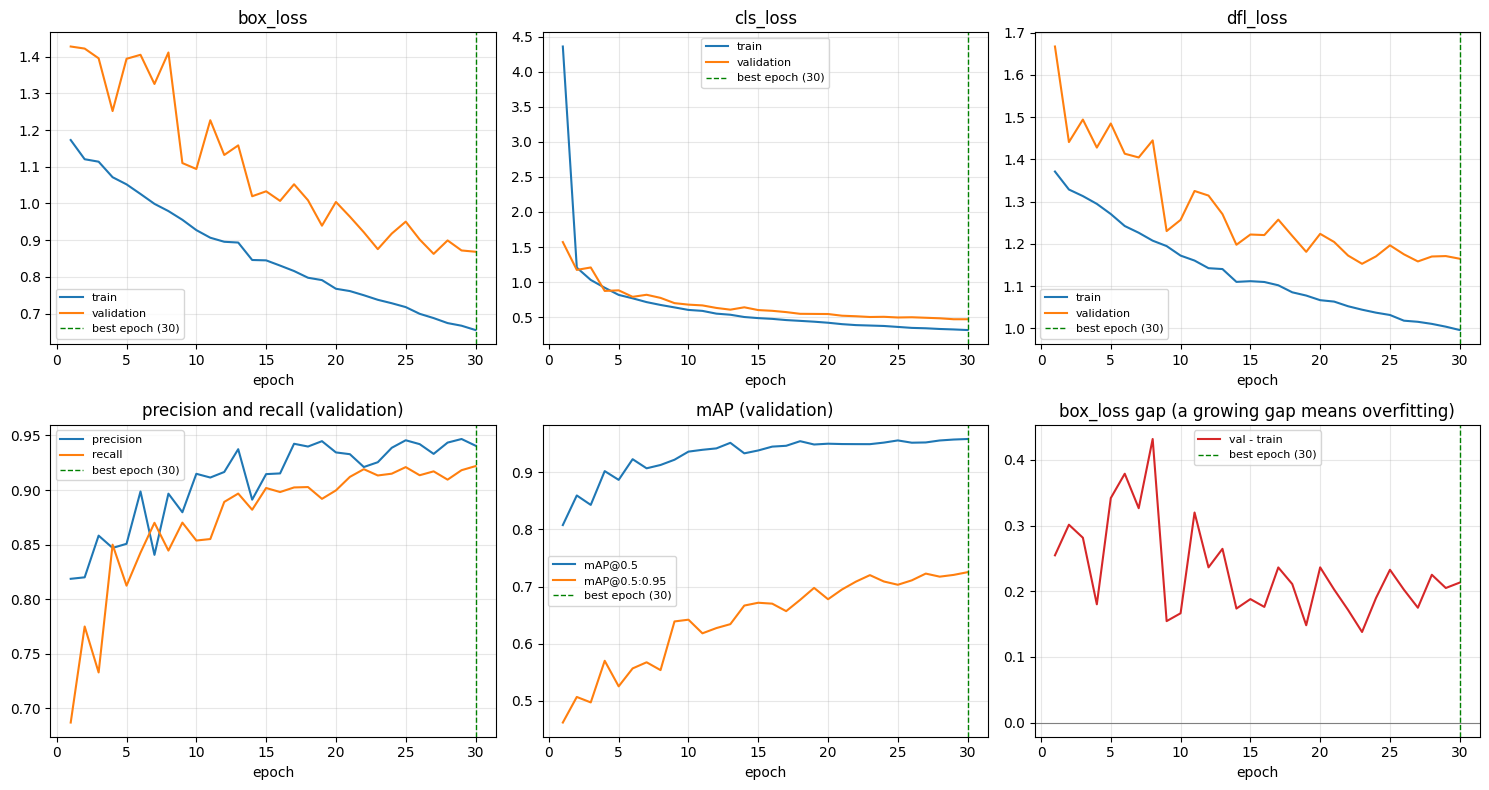

Epochs run: 30 | best epoch (best.pt): 30 | lowest val box_loss at epoch 27


In [22]:
from src.visualization import plot_training_curves

plot_training_curves(baseline["run_dir"])

## Second run, one setting changed

In [23]:
second = train_yolo(model_name="yolov8s.pt", run_name="yolov8s")
print("duration : %.1f min" % (second["duration_s"] / 60))
print(json.dumps(second["metrics"], indent=2))

Ultralytics 8.4.192 🚀 Python-3.10.22 torch-2.14.1+cu130 CUDA:0 (NVIDIA TITAN RTX, 24023MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/user/NeuroVision-AI-2/data/data.yaml, degrees=10.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.2, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=yolov8s, nbs=64, nms=None, opset=None, 

## Compare runs and register the champion

In [25]:
from src.mlflow_utils import compare_runs, register_champion

runs = compare_runs(experiment="neurovision-yolov8")     # DataFrame: params, recall, precision, mAP, duration
display(runs)

,run_id,run_name,model,precision,recall,map50,map50_95,best_epoch,duration_min
0,4da5d7c675d14d458b8508e94f3228f7,yolov8n-baseline,yolov8n.pt,0.9406,0.9219,0.9583,0.7253,30.0,10.8
1,7f604c96a8ee4883b188c3f7d4010b5d,yolov8s,yolov8s.pt,0.9439,0.9056,0.9506,0.7244,29.0,21.1
